# Lab 1 — Getting Started with Keras

### Include a Markdown cell below this with your name


### Google Colab Button section

#### Double click this to see the code for the button

You will be required to make your Google Colab button here. Please see how to do this on Canvas.  
Below is an example. It will not go anywhere because _username_, _repo_ and _path-to-file_ need to be updated.  
username is your github username.  
repo is the name of your repo.  
path-to-file is the path to the file. So if this was the (username) BS-CS (repo) CSB410_Labs repo, it would be Labs/week02_lab.ipynb.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/username/repo/blob/main/path-to-file)


## A.1 Colab / Environment Check


In [2]:
%pip install tensorflow

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
    --------------------------------------- 4.7/351.2 MB 29.8 MB/s eta 0:00:12
   - -------------------------------------- 11.8/351.2 MB 32.0 MB/s eta 0:00:11
   -- ------------------------------------- 19.7/351.2 MB 33.4 MB/s eta 0:00:10
   --- ------------------------------------ 28.3/351.2 MB 35.3 MB/s eta 0:00:10
   ---- ----------------------------------- 36.2/351.2 MB 35.6 MB/s eta 0:00:09
   ----- ---------------------------------- 45.1/351.2 MB 36.7 MB/s eta 0:00:09
   ------ --------------------------------- 53.7/351.2 MB 37.3 MB/s eta 0:00:08
   ------- -------------------------------- 62.1/351.2 MB 37.6 MB/s eta 0:00:08
   -------- ------------------------------- 71.0/351.2 MB 37.9 MB/s eta 0:00:08
   --------- ------------------------------ 80.0/351.2 MB 38.3 MB/s eta 0:00:08
   --------- ------------------------------ 87.0/351.2 MB 37.9 MB/s eta 0:00:07
   ---------- ----------------------------- 95.4/3

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.45.1 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [3]:
import sys, numpy as np, tensorflow as tf
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)

Python: 3.13.5
NumPy: 2.1.3
TensorFlow: 2.21.0


## A.2 Load and Inspect MNIST


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train: (60000, 28, 28) (60000,)
Test : (10000, 28, 28) (10000,)


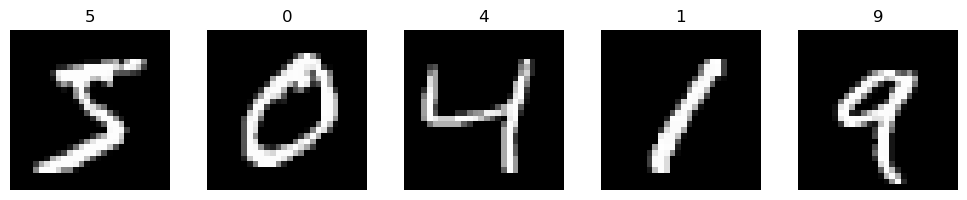

In [4]:

# TODO: load MNIST via keras.datasets and assign to x_train, y_train, x_test, y_test
from tensorflow import keras
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# TODO: print shapes
print("Train:", x_train.shape, y_train.shape)
print("Test :", x_test.shape, y_test.shape)

# TODO: visualize first 5 samples using matplotlib (grayscale)
import matplotlib.pyplot as plt
fig = plt.figure(figsize=(10,2))
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(int(y_train[i]))
    plt.axis("off")
plt.tight_layout()


## A.3 Preprocess Data


In [5]:

# TODO: normalize images to [0,1] and flatten to length 784
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0
x_train = x_train.reshape((x_train.shape[0], 784))
x_test  = x_test.reshape((x_test.shape[0], 784))
num_classes = 10

# Sanity checks (do not modify)
assert x_train.shape[1] == 784 and x_test.shape[1] == 784, "Flattening incorrect"
print("Flattened:", x_train.shape, x_test.shape)


Flattened: (60000, 784) (10000, 784)


## A.4 Build a Shallow Network


In [6]:

# TODO: build Sequential model: The Input will be 784.
# The first layer will be Dense of 128 neurons and use the ReLU activation function
# The second layer willbe Dense of 10 neurons and use the Softmax activation function
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## A.5 Compile and Train


In [7]:

# TODO: compile with Adam(1e-3). The loss will be Sparse Categorical Cross Entropy
# Compile with the metric of Accuracy
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# TODO: train for 5 epochs with validation split of 10% and batch size of 128
history = model.fit(x_train, y_train, validation_split=0.1, epochs=5, batch_size=128, verbose=2)


Epoch 1/5
422/422 - 2s - 5ms/step - accuracy: 0.8927 - loss: 0.3824 - val_accuracy: 0.9555 - val_loss: 0.1800
Epoch 2/5
422/422 - 1s - 3ms/step - accuracy: 0.9486 - loss: 0.1788 - val_accuracy: 0.9678 - val_loss: 0.1221
Epoch 3/5
422/422 - 1s - 3ms/step - accuracy: 0.9625 - loss: 0.1282 - val_accuracy: 0.9712 - val_loss: 0.1052
Epoch 4/5
422/422 - 1s - 3ms/step - accuracy: 0.9705 - loss: 0.0996 - val_accuracy: 0.9735 - val_loss: 0.0938
Epoch 5/5
422/422 - 1s - 3ms/step - accuracy: 0.9770 - loss: 0.0796 - val_accuracy: 0.9783 - val_loss: 0.0818


## A.6 Evaluate, Predict, Visualize


Test accuracy: 0.9700 | Test loss: 0.0925


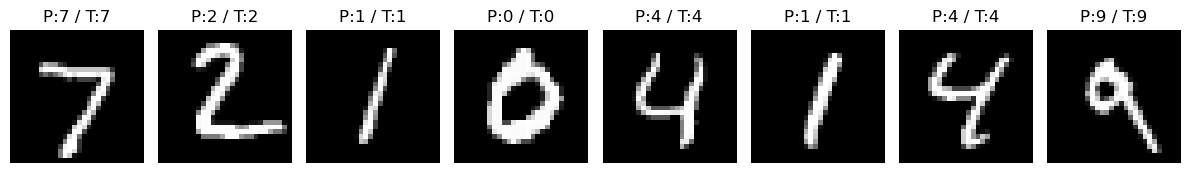

In [8]:

# TODO: evaluate on test set
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}")

# TODO: predict and convert to labels with argmax
import numpy as np, matplotlib.pyplot as plt
y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# TODO: show 8 images with predicted vs true labels
# Result should be Test accuracy: 0.9431 | Test loss: 0.1969 or something close
# and then pictures of numbers in the MNIST dataset
fig = plt.figure(figsize=(12,3))
for i in range(8):
    plt.subplot(1,8,i+1)
    plt.imshow(x_test.reshape(-1,28,28)[i], cmap="gray")  # x_test
    plt.title(f"P:{int(y_pred[i])} / T:{int(y_test[i])}")  # y_test
    plt.axis("off")
plt.tight_layout()


## A.7 Answer the following discussion questions in Markdown. Please ensure your answers are robust, being composted of a minimum of 3 sentences each.

1. Why is it important to normalize image pixel values to the range [0, 1] before training a neural network, and what might happen to model performance if normalization is skipped?
2. In the Week 2 model, we used a single hidden layer with 128 units and a ReLU activation. How might increasing or decreasing the number of units in this layer affect training speed, overfitting risk, and model accuracy?


1. it will help by making the neural network learn efficiently because the input values will be kept smaller and on consitent scale. Also when normalisation is skipped, the model might still learn but the training could become slower or less stable because of the large input values.

2. Neurons in computer work the same as neurons in human body. More neuron means more neuron connection which in return means learning complex things. So here by increasing or decreasing the number of neuron units, that is what we are essentially doing. But at the same time decreasing the number of neurons could also make training faster due to less parameters and ultimately reduce the risk of overfitting. So putting this things into consideration I would say using 128 neurons is a reasonable one for teh MNIST because it is relatively simple dataset and doesn't need large networks to achieve accuracy.